Generate rate-and-state friction training data following Liu et al. (2025).

Outputs an NPZ file containing train/validation/test velocity histories V(t),
state histories theta(t), and friction-coefficient histories f_RS(t).

Paper-matched settings:
  train/validation/test = 480/160/160 sequences
  100 samples per sequence, dt = 0.02 s
  V / V_ref in [1e-3, 1e1]
  a=0.011, b=0.016, f_ref=0.5109,
  V_ref=1e-4 m/s, D_RS=1e-6 m

The paper specifies two trajectory families but not every random-sampling detail.
This implementation uses a reproducible 50:50 mixture of:
  (1) logarithmic velocity-jump histories (piecewise constant log10(V/V_ref))
  (2) continuous histories whose log-velocity acceleration changes at random knots

Assumption: theta(0) = D_RS / V(0), i.e. initial steady state.

In [1]:

from __future__ import annotations

import argparse
import json
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np
import torch

try:
    from torchdiffeq import odeint
except ImportError as exc:
    raise SystemExit(
        "torchdiffeq is required. Install with: pip install torchdiffeq"
    ) from exc


In [2]:

@dataclass(frozen=True)
class RSFParameters:
    a: float = 0.011
    b: float = 0.016
    f_ref: float = 0.5109
    v_ref: float = 1.0e-4
    d_rs: float = 1.0e-6


In [3]:


DT = 0.02
N_TIME = 100
LOG_RATIO_MIN = -3.0
LOG_RATIO_MAX = 1.0


In [4]:


def velocity_jump_history(t: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Piecewise-constant velocity with jumps sampled uniformly in log10 space."""
    n_jumps = int(rng.integers(2, 7))
    jump_indices = np.sort(
        rng.choice(np.arange(5, len(t) - 5), size=n_jumps, replace=False)
    )
    levels = rng.uniform(LOG_RATIO_MIN, LOG_RATIO_MAX, size=n_jumps + 1)

    log_ratio = np.full(len(t), levels[0], dtype=np.float64)
    for idx, level in zip(jump_indices, levels[1:]):
        log_ratio[idx:] = level
    return 10.0 ** log_ratio



In [ ]:

def continuous_variation_history(t: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Continuous log-velocity with piecewise-constant random acceleration.

    The acceleration of y=log10(V/V_ref) changes at randomly sampled knot times.
    Reflection at y=-3 and y=1 keeps the prescribed velocity range while avoiding
    long flat segments caused by hard clipping.
    """
    n_segments = int(rng.integers(4, 9))
    interior = np.sort(
        rng.choice(np.arange(5, len(t) - 5), size=n_segments - 1, replace=False)
    )
    boundaries = np.r_[0, interior, len(t)]
    accelerations = rng.uniform(-8.0, 8.0, size=n_segments)  # log10 units / s^2

    y = np.empty(len(t), dtype=np.float64)
    y[0] = rng.uniform(LOG_RATIO_MIN, LOG_RATIO_MAX)
    y_dot = rng.uniform(-1.5, 1.5)  # log10 units / s

    seg = 0
    for i in range(1, len(t)):
        if i >= boundaries[seg + 1]:
            seg += 1
        y_dot += accelerations[seg] * DT
        y[i] = y[i - 1] + y_dot * DT

        # Reflect at the bounds to retain smooth, non-flat trajectories.
        if y[i] > LOG_RATIO_MAX:
            y[i] = 2.0 * LOG_RATIO_MAX - y[i]
            y_dot *= -1.0
        elif y[i] < LOG_RATIO_MIN:
            y[i] = 2.0 * LOG_RATIO_MIN - y[i]
            y_dot *= -1.0
        y[i] = np.clip(y[i], LOG_RATIO_MIN, LOG_RATIO_MAX)

    return 10.0 ** y


In [13]:

def integrate_state_and_friction(
    t_np: np.ndarray,
    velocity_ratio: np.ndarray,
    p: RSFParameters,
    history_kind: str,
    dtype: torch.dtype = torch.float64,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Integrate the aging law and evaluate the RSF friction coefficient."""
    device = torch.device("cpu")
    t = torch.as_tensor(t_np, dtype=dtype, device=device)
    ratio = torch.as_tensor(velocity_ratio, dtype=dtype, device=device)
    velocity = p.v_ref * ratio

    def velocity_at(time: torch.Tensor) -> torch.Tensor:
        u = torch.clamp(time / DT, 0.0, N_TIME - 1.0)
        i0 = torch.floor(u).long()
        if history_kind == "jump":
            # Zero-order hold reproduces a sum of Heaviside functions.
            return velocity[i0]
        i1 = torch.clamp(i0 + 1, max=N_TIME - 1)
        w = u - i0.to(dtype)
        return velocity[i0] * (1.0 - w) + velocity[i1] * w

    def aging_law(time: torch.Tensor, theta: torch.Tensor) -> torch.Tensor:
        v = velocity_at(time)
        return 1.0 - v * theta / p.d_rs

    theta0 = torch.tensor([p.d_rs / float(velocity[0])], dtype=dtype, device=device)
    theta = odeint(aging_law, theta0, t, method="dopri5", rtol=1e-9, atol=1e-11)[:, 0]

    friction = (
        p.f_ref
        + p.a * torch.log(velocity / p.v_ref)
        + p.b * torch.log(p.v_ref * theta / p.d_rs)
    )
    return (
        velocity.cpu().numpy(),
        theta.cpu().numpy(),
        friction.cpu().numpy(),
    )


In [6]:

def make_split(
    n_sequences: int,
    t: np.ndarray,
    rng: np.random.Generator,
    p: RSFParameters,
) -> dict[str, np.ndarray]:
    velocities = np.empty((n_sequences, N_TIME), dtype=np.float64)
    states = np.empty_like(velocities)
    frictions = np.empty_like(velocities)
    kind = np.empty(n_sequences, dtype="U10")

    labels = np.array(["jump"] * (n_sequences // 2) + ["continuous"] * (n_sequences - n_sequences // 2))
    rng.shuffle(labels)

    for i, label in enumerate(labels):
        ratio = (
            velocity_jump_history(t, rng)
            if label == "jump"
            else continuous_variation_history(t, rng)
        )
        v, theta, f_rs = integrate_state_and_friction(t, ratio, p, label)
        velocities[i] = v
        states[i] = theta
        frictions[i] = f_rs
        kind[i] = label

    return {"V": velocities, "theta": states, "f_RS": frictions, "kind": kind}


In [7]:

def validate_dataset(data: dict[str, np.ndarray], p: RSFParameters) -> None:
    """Secondary consistency checks on dimensions, finiteness, and velocity range."""
    for split, expected_n in (("train", 480), ("val", 160), ("test", 160)):
        for name in ("V", "theta", "f_RS"):
            x = data[f"{split}_{name}"]
            assert x.shape == (expected_n, N_TIME), (split, name, x.shape)
            assert np.isfinite(x).all(), f"Non-finite values in {split}_{name}"
        ratio = data[f"{split}_V"] / p.v_ref
        assert ratio.min() >= 1e-3 * (1.0 - 1e-12)
        assert ratio.max() <= 1e1 * (1.0 + 1e-12)
        assert (data[f"{split}_theta"] > 0.0).all()



In [11]:

def main() -> None:
    # parser = argparse.ArgumentParser()
    # parser.add_argument("--output", type=Path, default=Path("liu2025_rsf_dataset.npz"))
    # parser.add_argument("--seed", type=int, default=2025)
    # args = parser.parse_args()
    args = {
        "seed": 2025,
        "output": r"E:\SPReAD\261030\output.npz"
    }

    p = RSFParameters()
    rng = np.random.default_rng(args["seed"])
    t = np.arange(N_TIME, dtype=np.float64) * DT

    out: dict[str, np.ndarray] = {"t": t}
    for split, n in (("train", 480), ("val", 160), ("test", 160)):
        split_data = make_split(n, t, rng, p)
        for name, values in split_data.items():
            out[f"{split}_{name}"] = values

    metadata = {
        "source": "Liu et al. (2025), DOI: 10.1016/j.mechmat.2025.105540",
        "parameters": asdict(p),
        "dt_s": DT,
        "n_time": N_TIME,
        "time_interval_s": [float(t[0]), float(t[-1])],
        "velocity_ratio_range": [1e-3, 1e1],
        "theta_initialization": "theta0 = D_RS / V(0) (assumption: initial steady state)",
        "trajectory_mixture": "50% logarithmic jumps, 50% continuous random-acceleration histories",
        "seed": args["seed"],
    }
    out["metadata_json"] = np.array(json.dumps(metadata, indent=2))

    validate_dataset(out, p)
    np.savez_compressed(args["output"], **out)
    print(f"Saved: {args["output"]}")
    print("train_V/train_f_RS:", out["train_V"].shape, out["train_f_RS"].shape)
    print("val_V/val_f_RS:    ", out["val_V"].shape, out["val_f_RS"].shape)
    print("test_V/test_f_RS:  ", out["test_V"].shape, out["test_f_RS"].shape)


In [14]:
main()

Saved: E:\SPReAD\261030\output.npz
train_V/train_f_RS: (480, 100) (480, 100)
val_V/val_f_RS:     (160, 100) (160, 100)
test_V/test_f_RS:   (160, 100) (160, 100)


## データの読み込み

In [ ]:
import numpy as np

data = np.load(
    r"E:\SPReAD\261030\output_01.npz",
    allow_pickle=False,
)

t = data["t"]

V_train = data["train_V"]
theta_train = data["train_theta"]
f_train = data["train_f_RS"]

print(t.shape)
print(V_train.shape)
print(theta_train.shape)
print(f_train.shape)

(100,)
(480, 100)
(480, 100)
(480, 100)


# 出力のグラフ化

In [16]:
epochs = [
    1,50,100,150
]
trains = [
    9.1494e+00,
    1.0770e+00,
    1.5754e+00,
    2.1459e-01
]
vals = [
    1.0624e+00,
    2.8026e-01,
    1.2824e-01,
    6.4272e-02
]

In [18]:
import matplotlib.pyplot as plt

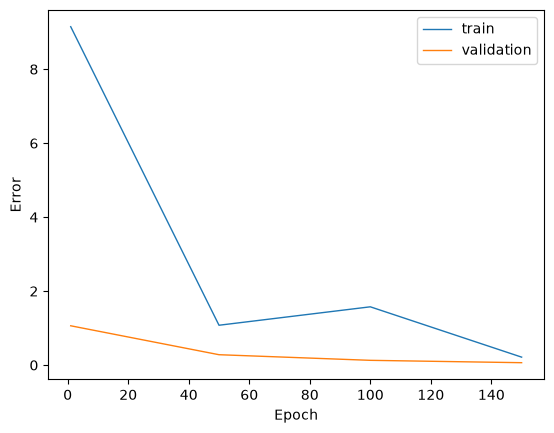

In [29]:
fig, ax = plt.subplots()

ax.plot(epochs, trains, lw = 1, c = "tab:blue", label = "train")
ax.plot(epochs, vals, lw = 1, c = "tab:orange", label = "validation")
ax.legend()

ax.set_xlabel("Epoch")
ax.set_ylabel("Error")
# ax.set_yscale("log")

plt.show()